# RQ1: Evolution Across Releases

This notebook analyses how the accuracy, the energy and the intelligence efficiency of the models evolved across releases, per size category.

The process consists of:
1. **Accuracy**: Plotting the accuracy of every model run against its release date.
2. **Energy per Question**: Plotting the distribution of the GPU energy per question of every model run, per size category.
3. **Intelligence Efficiency**: Plotting the correct answers per kJ against the release date, with the best value so far.
4. **Trends**: Estimating the yearly change of each metric per size category.
5. **Response Length and Energy per Token**: Plotting the two factors of the energy per question against the release date.
6. **Decomposition by Lineage**: Splitting the change of intelligence efficiency between successive releases of the same family into its three factors.
7. **Decomposition by Release Year**: Doing the same between the release years of each size category.
8. **Energy per Token at Equal Size**: Removing the effect of the size of the model from the energy per token, over time and in the lineage steps.
9. **Pareto Front per Year**: Finding the Pareto front of the model runs released until the end of each year.
10. **Accuracy within an Energy Budget**: Finding the best accuracy among the model runs released so far, for every energy budget.
11. **Earlier and Later Models**: Comparing the earlier and the later models of each size category, by their medians and at fixed energy budgets.
12. **Typical Response Length**: Comparing the mean and the median of the generated tokens of a question, by release year and in the trends.
13. **Examples of the Prompt**: Comparing the length of the responses of the instruct runs with that of the answers of the examples of their prompt.
14. **Key Values**: Printing the main values of this notebook.

### Setup & Imports
We load the tables built by `00-dataset.ipynb` and the chart helpers of `common.py`. Trends are fitted on the instruct runs, which exist over the whole period.

In [1]:
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
from matplotlib.colors import BoundaryNorm, LinearSegmentedColormap
from matplotlib.lines import Line2D
from matplotlib.patches import Patch
from scipy.stats import spearmanr

from common import (
    BUDGETS_KJ,
    CATEGORY_COLORS,
    CATEGORY_ORDER,
    FACTOR_COLORS,
    FAMILY_MARKERS,
    FAMILY_ORDER,
    LOG_TICK_LABELS,
    LOG_TICKS,
    SCATTER_STYLE,
    TARGET_COLORS,
    category_panels,
    chance_level,
    contributions,
    factor_handles,
    format_year_axis,
    legend_handles,
    lineages,
    load_model_runs,
    load_questions,
    pareto_front,
    percent_axis,
    plain_log_axis,
    save_chart,
    scatter_model_runs,
    short_name,
    stacked_contributions,
    with_log_factors,
)

model_runs = load_model_runs()
questions = load_questions(model_runs)

CHANCE_LEVEL = chance_level(questions)
FAMILIES = [family for family in FAMILY_ORDER if family in set(model_runs["family"])]

# Release date in years, for the trends
model_runs["years"] = (model_runs["release_date"] - pd.Timestamp("2023-01-01")).dt.days / 365.25
model_runs["year"] = model_runs["release_date"].dt.year
instruct = model_runs[model_runs["mode"] == "Instruct"]

print(f"Model runs: {len(model_runs)}   instruct: {len(instruct)}   reasoning: {len(model_runs) - len(instruct)}")
print(f"Release dates: {model_runs['release_date'].min().date()} to {model_runs['release_date'].max().date()}")


def plot_over_time(axes, column, log=False):
    # One panel per size category, with a line joining the instruct releases of each lineage
    for ax, category in zip(axes, CATEGORY_ORDER):
        runs = model_runs[model_runs["category"] == category]
        for _, lineage_category, _, lineage in lineages(model_runs):
            if lineage_category == category:
                ax.plot(lineage["release_date"], lineage[column], color="0.75", linewidth=1, zorder=1)
        scatter_model_runs(ax, runs, "release_date", column, zorder=2)
        format_year_axis(ax)
        if log:
            ax.set_yscale("log")
            plain_log_axis(ax.yaxis)


def add_legend(fig, extra=(), bottom=0.17):
    handles = legend_handles(categories=False, families=FAMILIES)
    handles.append(Line2D([], [], color="0.75", linewidth=1, label="Successive releases of a family"))
    handles.extend(extra)
    fig.legend(handles=handles, loc="lower center", ncol=5, fontsize=9, frameon=False)
    plt.tight_layout(rect=(0, bottom, 1, 1))

Model runs: 53   instruct: 38   reasoning: 15
Release dates: 2023-07-13 to 2026-03-02


### 1. Accuracy
We plot the accuracy of every model run against its release date, with one panel per size category. Lines join the successive instruct releases of the same family and architecture, and the horizontal line is the chance level.

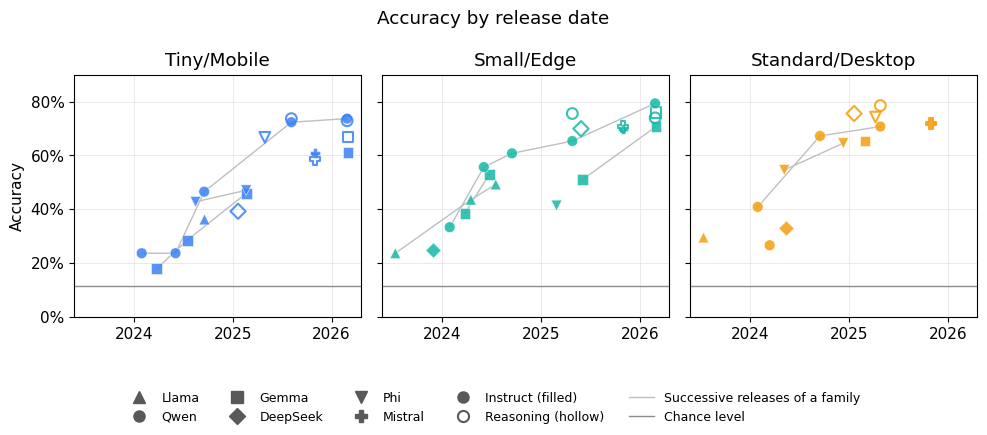

In [2]:
fig, axes = category_panels(figsize=(10, 4.3))
plot_over_time(axes[0], "accuracy")
for ax in axes[0]:
    ax.axhline(CHANCE_LEVEL, color="0.55", linewidth=1)
    ax.set_ylim(0, 0.9)
    percent_axis(ax.yaxis)
axes[0][0].set_ylabel("Accuracy")
fig.suptitle("Accuracy by release date")
add_legend(fig, extra=[Line2D([], [], color="0.55", linewidth=1, label="Chance level")])
save_chart(fig, "rq1-accuracy")
plt.show()

### 2. Energy per Question
We plot the GPU energy per question of every model run against its release date (log scale), with one panel per size category.

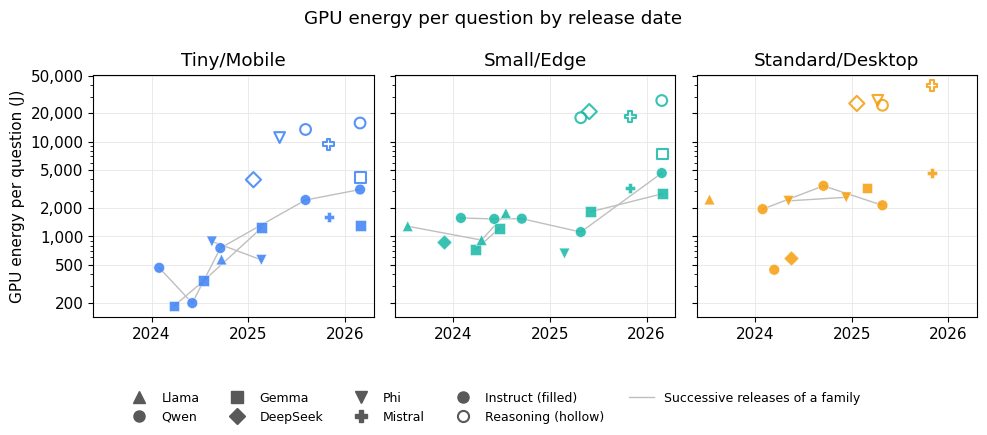

In [3]:
fig, axes = category_panels(figsize=(10, 4.3))
plot_over_time(axes[0], "gpu_joules_per_question", log=True)
axes[0][0].set_ylabel("GPU energy per question (J)")
fig.suptitle("GPU energy per question by release date")
add_legend(fig)
save_chart(fig, "rq1-energy-per-question")
plt.show()

We plot the distribution of the GPU energy per question of every model run, ordered by release date, with one figure per size category. Each box summarizes the 372 questions, using the median of the repetitions of each question: the box spans the quartiles, the whiskers the minimum and maximum, and the diamond marks the mean. Reasoning runs are drawn hollow. The three figures share the same horizontal axis.

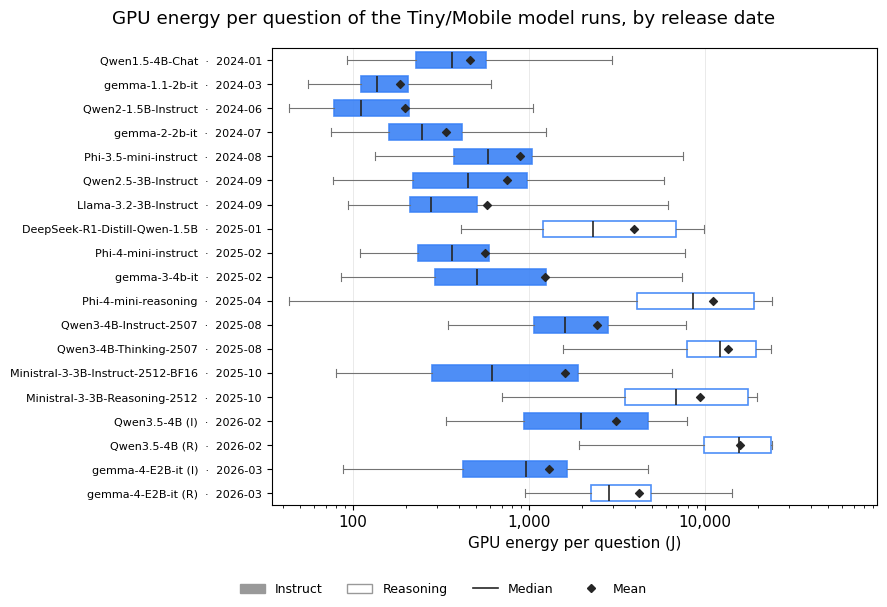

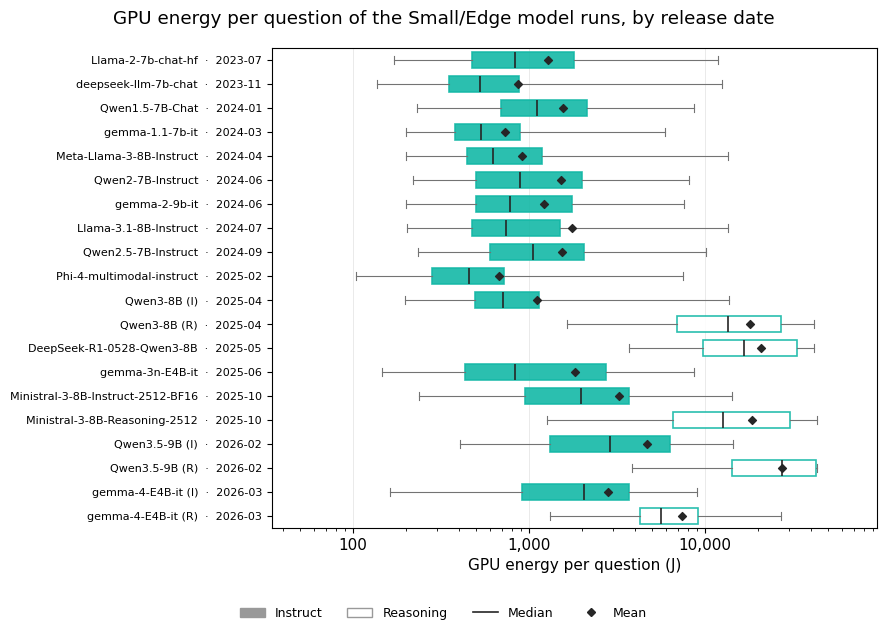

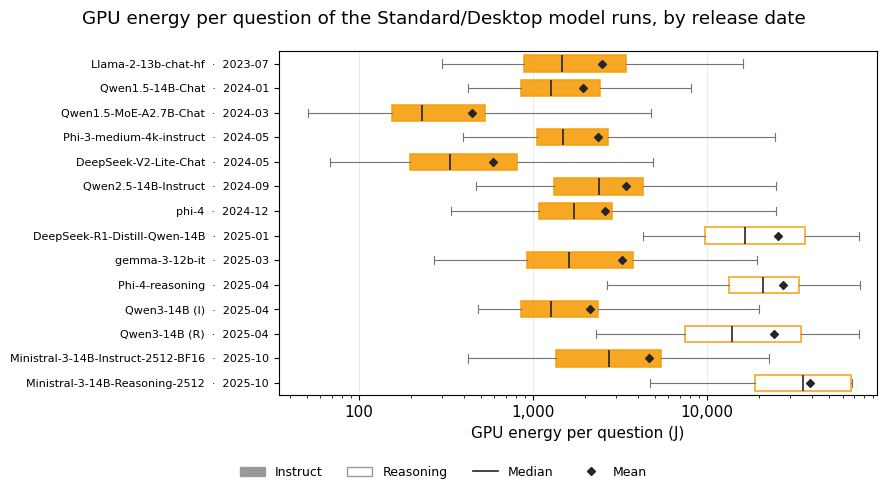

In [4]:
BOX_HANDLES = [
    Patch(facecolor="0.6", edgecolor="0.6", label="Instruct"),
    Patch(facecolor="white", edgecolor="0.6", label="Reasoning"),
    Line2D([], [], color="0.15", linewidth=1.2, label="Median"),
    Line2D([], [], marker="D", linestyle="", markersize=4, color="0.15", label="Mean"),
]
# Same horizontal axis in the three figures
energy_limits = (0.8 * questions["gpu_joules_median"].min(), 1.25 * questions["gpu_joules_median"].max())

for category in CATEGORY_ORDER:
    runs = model_runs[model_runs["category"] == category].sort_values(["release_date", "model_run"], ascending=[False, False])
    color = CATEGORY_COLORS[category]
    data = [questions.loc[questions["model_run"] == run, "gpu_joules_median"].to_numpy() for run in runs["model_run"]]

    fig, ax = plt.subplots(figsize=(9, 0.24 * len(runs) + 1.5))
    boxes = ax.boxplot(
        data,
        orientation="horizontal",
        whis=(0, 100),
        widths=0.66,
        patch_artist=True,
        medianprops=dict(color="0.15", linewidth=1.2),
        whiskerprops=dict(color="0.45", linewidth=0.8),
        capprops=dict(color="0.45", linewidth=0.8),
    )
    for box, mode in zip(boxes["boxes"], runs["mode"]):
        box.set(facecolor=color if mode == "Instruct" else "white", edgecolor=color, linewidth=1.2, alpha=0.9)
    positions = np.arange(1, len(runs) + 1)
    ax.scatter(runs["gpu_joules_per_question"], positions, marker="D", s=16, color="0.15", zorder=3)
    labels = [f"{short_name(run)}  ·  {date:%Y-%m}" for run, date in zip(runs["model_run"], runs["release_date"])]
    ax.set_yticks(positions, labels=labels, fontsize=8)
    ax.set_xscale("log")
    plain_log_axis(ax.xaxis, subs=(1,))
    ax.set_xlim(*energy_limits)
    ax.grid(axis="y", visible=False)
    ax.set_xlabel("GPU energy per question (J)")
    fig.suptitle(f"GPU energy per question of the {category} model runs, by release date")
    fig.legend(handles=BOX_HANDLES, loc="lower center", ncol=4, fontsize=9, frameon=False)
    plt.tight_layout(rect=(0, 0.06, 1, 1))
    save_chart(fig, f"rq1-energy-per-question-{category.lower().replace('/', '-')}")
    plt.show()

### 3. Intelligence Efficiency
We plot the correct answers per kJ of GPU energy against the release date (log scale). The dashed line is the best value among the models released so far in each size category.

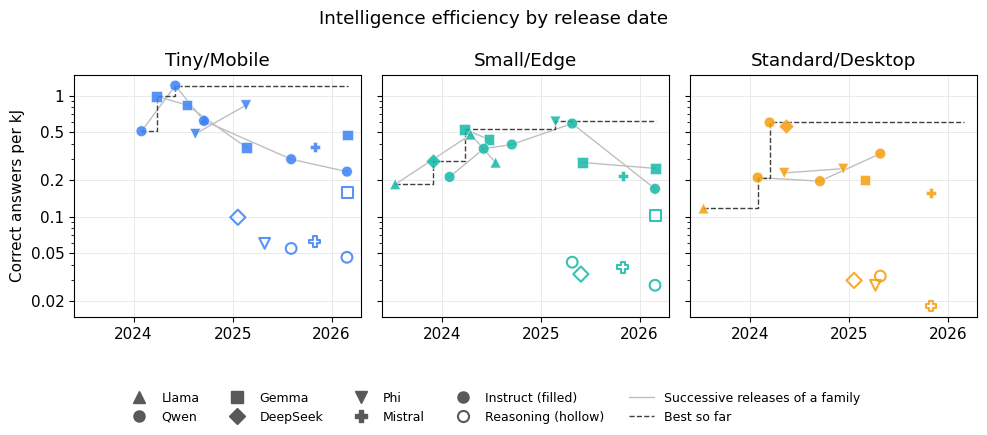

In [5]:
fig, axes = category_panels(figsize=(10, 4.3))
plot_over_time(axes[0], "correct_answers_per_kj", log=True)
last_date = model_runs["release_date"].max()
for ax, category in zip(axes[0], CATEGORY_ORDER):
    runs = model_runs[model_runs["category"] == category].sort_values("release_date")
    dates = list(runs["release_date"]) + [last_date]
    best = list(runs["correct_answers_per_kj"].cummax())
    ax.step(dates, best + best[-1:], where="post", color="0.25", linewidth=1, linestyle="--", zorder=1)
axes[0][0].set_ylabel("Correct answers per kJ")
fig.suptitle("Intelligence efficiency by release date")
add_legend(fig, extra=[Line2D([], [], color="0.25", linewidth=1, linestyle="--", label="Best so far")])
save_chart(fig, "rq1-intelligence-efficiency")
plt.show()

### 4. Trends
We estimate the yearly change of each metric among the instruct runs of each size category, with a straight line fitted against the release date. Accuracy is fitted on a linear scale (points per year) and the other metrics on a log scale (factor per year). Spearman's rank correlation measures the association between the metric and the release date.

In [6]:
METRICS = {
    "Accuracy": ("accuracy", False),
    "GPU energy per question": ("gpu_joules_per_question", True),
    "Generated tokens per question": ("generated_tokens_per_question", True),
    "GPU energy per generated token": ("gpu_joules_per_generated_token", True),
    "Correct answers per kJ": ("correct_answers_per_kj", True),
}


def yearly_change(runs, column, log):
    x = runs["years"].to_numpy()
    y = np.log(runs[column].to_numpy()) if log else 100 * runs[column].to_numpy()
    slope = np.polyfit(x, y, 1)[0]
    correlation, p_value = spearmanr(x, y)
    return (np.exp(slope) if log else slope), correlation, p_value


def trend_table(runs):
    rows = []
    for category in CATEGORY_ORDER:
        category_runs = runs[runs["category"] == category]
        for name, (column, log) in METRICS.items():
            slope, correlation, p_value = yearly_change(category_runs, column, log)
            rows.append({
                "Category": category,
                "Metric": name,
                "Model runs": len(category_runs),
                "Yearly change": f"×{slope:.2f}" if log else f"{slope:+.1f} points",
                "Spearman correlation": round(correlation, 2),
                "p": round(p_value, 3),
            })
    return pd.DataFrame(rows)


trends = trend_table(instruct)
trends.set_index(["Category", "Metric"])

Model runs Yearly change  \
Category         Metric                                                     
Tiny/Mobile      Accuracy                                13  +23.9 points   
                 GPU energy per question                 13         ×2.84   
                 Generated tokens per question           13         ×2.56   
                 GPU energy per generated token          13         ×1.11   
                 Correct answers per kJ                  13         ×0.62   
Small/Edge       Accuracy                                15  +17.9 points   
                 GPU energy per question                 15         ×1.57   
                 Generated tokens per question           15         ×1.73   
                 GPU energy per generated token          15         ×0.91   
                 Correct answers per kJ                  15         ×0.93   
Standard/Desktop Accuracy                                10  +22.9 points   
                 GPU energy per question                 10         ×1.67   
                 Generated tokens per question           10         ×1.30   
                 GPU energy per generated token          10         ×1.28   
                 Correct answers per kJ                  10         ×0.96   

                                                 Spearman correlation      p  
Category         Metric                                                       
Tiny/Mobile      Accuracy                                        0.92  0.000  
                 GPU energy per question                         0.87  0.000  
                 Generated tokens per question                   0.91  0.000  
                 GPU energy per generated token                  0.36  0.223  
                 Correct answers per kJ                         -0.74  0.004  
Small/Edge       Accuracy                                        0.87  0.000  
                 GPU energy per question                         0.59  0.020  
                 Generated tokens per question                   0.69  0.004  
                 GPU energy per generated token                 -0.02  0.940  
                 Correct answers per kJ                         -0.08  0.771  
Standard/Desktop Accuracy                                        0.88  0.001  
                 GPU energy per question                         0.55  0.098  
                 Generated tokens per question                   0.47  0.174  
                 GPU energy per generated token                  0.15  0.676  
                 Correct answers per kJ                         -0.02  0.960

The same estimates without the sparsely activated models:

In [7]:
dense_trends = trend_table(instruct[instruct["architecture"] == "Dense"])
dense_trends.set_index(["Category", "Metric"])

Model runs Yearly change  \
Category         Metric                                                     
Tiny/Mobile      Accuracy                                12  +26.8 points   
                 GPU energy per question                 12         ×3.36   
                 Generated tokens per question           12         ×2.74   
                 GPU energy per generated token          12         ×1.23   
                 Correct answers per kJ                  12         ×0.56   
Small/Edge       Accuracy                                13  +20.0 points   
                 GPU energy per question                 13         ×1.57   
                 Generated tokens per question           13         ×1.59   
                 GPU energy per generated token          13         ×0.98   
                 Correct answers per kJ                  13         ×0.98   
Standard/Desktop Accuracy                                 8  +19.4 points   
                 GPU energy per question                  8         ×1.26   
                 Generated tokens per question            8         ×1.30   
                 GPU energy per generated token           8         ×0.97   
                 Correct answers per kJ                   8         ×1.18   

                                                 Spearman correlation      p  
Category         Metric                                                       
Tiny/Mobile      Accuracy                                        0.93  0.000  
                 GPU energy per question                         0.88  0.000  
                 Generated tokens per question                   0.91  0.000  
                 GPU energy per generated token                  0.66  0.018  
                 Correct answers per kJ                         -0.73  0.007  
Small/Edge       Accuracy                                        0.90  0.000  
                 GPU energy per question                         0.39  0.188  
                 Generated tokens per question                   0.53  0.061  
                 GPU energy per generated token                  0.34  0.263  
                 Correct answers per kJ                          0.11  0.721  
Standard/Desktop Accuracy                                        0.93  0.001  
                 GPU energy per question                         0.48  0.233  
                 Generated tokens per question                   0.43  0.289  
                 GPU energy per generated token                 -0.10  0.823  
                 Correct answers per kJ                          0.24  0.570

### 5. Response Length and Energy per Token
The GPU energy per question is the product of two factors: the generated tokens per question and the GPU energy per generated token. We plot each of them against the release date (log scale).

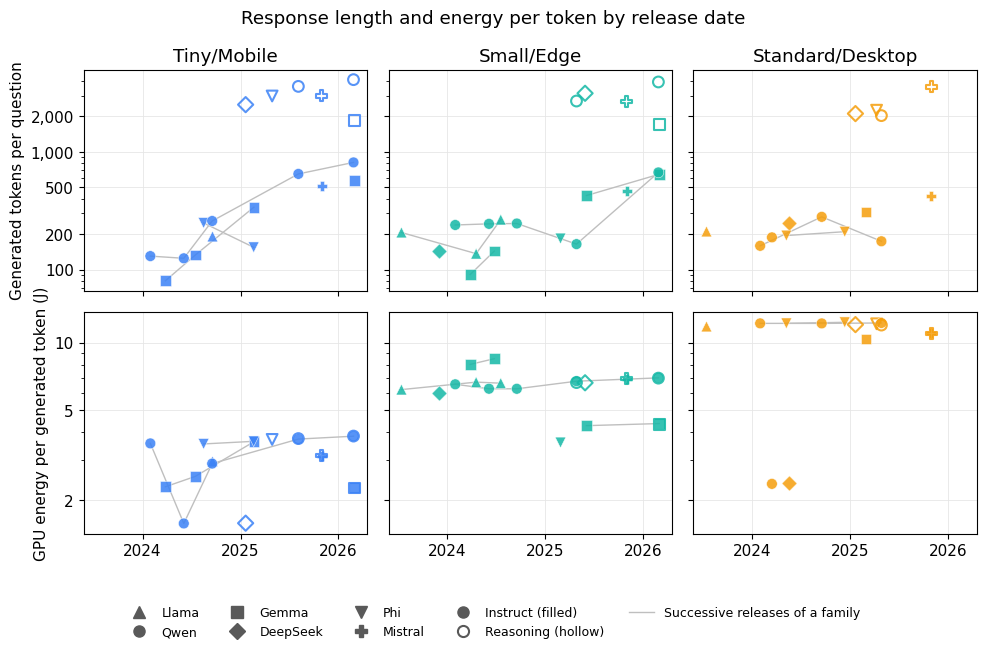

In [8]:
fig, axes = category_panels(nrows=2, figsize=(10, 6.5))
plot_over_time(axes[0], "generated_tokens_per_question", log=True)
plot_over_time(axes[1], "gpu_joules_per_generated_token", log=True)
axes[0][0].set_ylabel("Generated tokens per question")
axes[1][0].set_ylabel("GPU energy per generated token (J)")
fig.suptitle("Response length and energy per token by release date")
add_legend(fig, bottom=0.11)
save_chart(fig, "rq1-tokens-and-energy-per-token")
plt.show()

### 6. Decomposition by Lineage
Intelligence efficiency = accuracy ÷ (generated tokens per question × GPU energy per generated token). On a log scale, its change between two model runs is the sum of three contributions: accuracy, response length and energy per token. We compute them between successive instruct releases of the same family, size category and architecture. Each model run enters with the geometric mean of its repetitions, for which the sum is exact. The table lists every step, with each contribution as a factor (above 1 improves the intelligence efficiency).

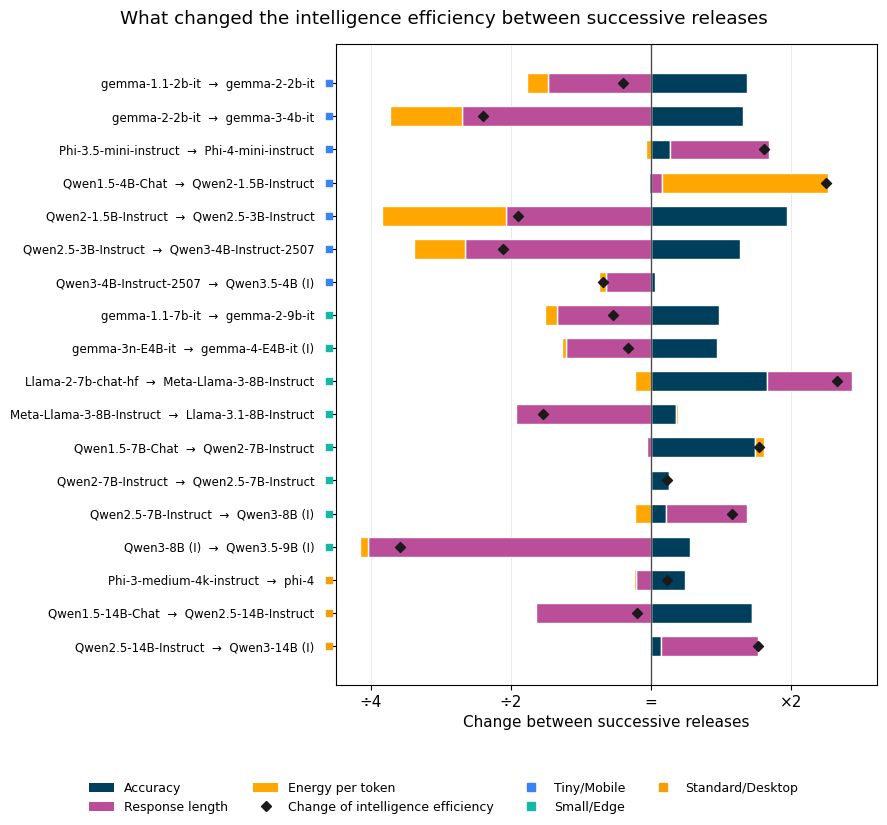

,category,family,from,to,Accuracy,Response length,Energy per token,Net
0,Tiny/Mobile,Gemma,gemma-1.1-2b-it,gemma-2-2b-it,1.61,0.60,0.90,0.87
1,Tiny/Mobile,Gemma,gemma-2-2b-it,gemma-3-4b-it,1.58,0.39,0.70,0.44
2,Tiny/Mobile,Phi,Phi-3.5-mini-instruct,Phi-4-mini-instruct,1.10,1.64,0.97,1.75
3,Tiny/Mobile,Qwen,Qwen1.5-4B-Chat,Qwen2-1.5B-Instruct,0.99,1.06,2.27,2.37
4,Tiny/Mobile,Qwen,Qwen2-1.5B-Instruct,Qwen2.5-3B-Instruct,1.96,0.49,0.54,0.52
5,Tiny/Mobile,Qwen,Qwen2.5-3B-Instruct,Qwen3-4B-Instruct-2507,1.55,0.40,0.78,0.48
6,Tiny/Mobile,Qwen,Qwen3-4B-Instruct-2507,Qwen3.5-4B (I),1.02,0.80,0.97,0.79
7,Small/Edge,Gemma,gemma-1.1-7b-it,gemma-2-9b-it,1.40,0.63,0.94,0.83
8,Small/Edge,Gemma,gemma-3n-E4B-it,gemma-4-E4B-it (I),1.38,0.66,0.98,0.89
9,Small/Edge,Llama,Llama-2-7b-chat-hf,Meta-Llama-3-8B-Instruct,1.77,1.53,0.93,2.51


In [9]:
model_runs = with_log_factors(model_runs)
instruct = model_runs[model_runs["mode"] == "Instruct"]
FACTOR_HANDLES = factor_handles()

rows = []
for family, category, architecture, lineage in lineages(model_runs):
    for (_, before), (_, after) in zip(lineage.iloc[:-1].iterrows(), lineage.iloc[1:].iterrows()):
        rows.append({
            "family": family,
            "category": category,
            "architecture": architecture,
            "from": short_name(before["model_run"]),
            "to": short_name(after["model_run"]),
            "from_run": before["model_run"],
            "to_run": after["model_run"],
            "to_date": after["release_date"],
            **contributions(before, after),
        })
steps = pd.DataFrame(rows)
steps["category"] = pd.Categorical(steps["category"], CATEGORY_ORDER, ordered=True)
steps = steps.sort_values(["category", "family", "to_date"]).reset_index(drop=True)
assert np.allclose(steps[list(FACTOR_COLORS)].sum(axis=1), steps["Net"])

fig, ax = plt.subplots(figsize=(9, 0.36 * len(steps) + 1.8))
table = steps.iloc[::-1].reset_index(drop=True)
positions = stacked_contributions(ax, table, horizontal=True)
ax.set_yticks(positions, labels=[f"{a}  →  {b}" for a, b in zip(table["from"], table["to"])], fontsize=8.5)
for position, category in zip(positions, table["category"]):
    ax.scatter(-0.012, position, transform=ax.get_yaxis_transform(), marker="s", s=22, color=CATEGORY_COLORS[category], clip_on=False)
ax.tick_params(axis="y", pad=12)
ax.grid(axis="y", visible=False)
ax.set_xlabel("Change between successive releases")
fig.suptitle("What changed the intelligence efficiency between successive releases")
handles = FACTOR_HANDLES + [Line2D([], [], marker="s", linestyle="", markersize=6, color=CATEGORY_COLORS[c], label=c) for c in CATEGORY_ORDER]
fig.legend(handles=handles, loc="lower center", ncol=4, fontsize=9, frameon=False)
plt.tight_layout(rect=(0, 0.09, 1, 1))
save_chart(fig, "rq1-decomposition-by-lineage")
plt.show()

lineage_table = steps[["category", "family", "from", "to"]].copy()
for factor in list(FACTOR_COLORS) + ["Net"]:
    lineage_table[factor] = np.exp(steps[factor]).round(2)
lineage_table

We also plot each step by its two kinds of contribution: the behaviour of the model (accuracy and response length together) against the energy per token. Steps above the diagonal improved the intelligence efficiency.

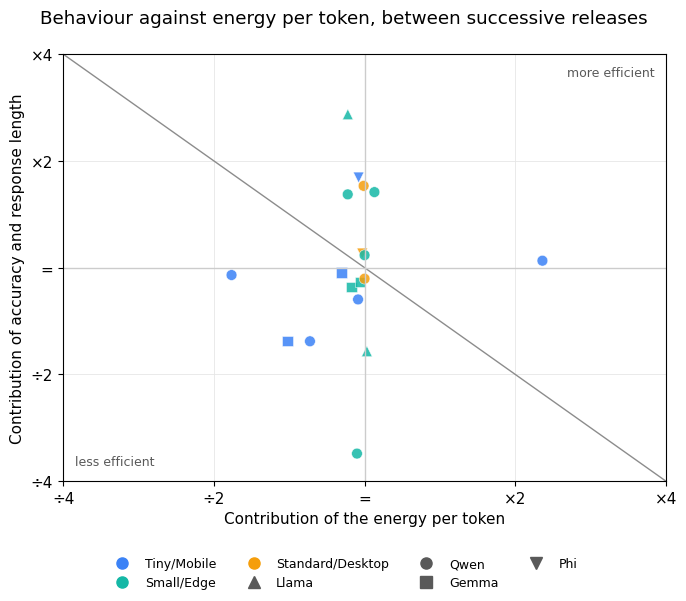

Steps: 18   intelligence efficiency improved in: 8
Accuracy improved in: 17   responses got longer in: 13   energy per token fell in: 5


In [10]:
steps["Behaviour"] = steps["Accuracy"] + steps["Response length"]

fig, ax = plt.subplots(figsize=(7, 6))
limit = 1.15 * max(steps["Behaviour"].abs().max(), steps["Energy per token"].abs().max())
ax.plot([-limit, limit], [limit, -limit], color="0.55", linewidth=1)
ax.axhline(0, color="0.8", linewidth=1)
ax.axvline(0, color="0.8", linewidth=1)
for family, group in steps.groupby("family"):
    ax.scatter(group["Energy per token"], group["Behaviour"], c=group["category"].astype(str).map(CATEGORY_COLORS), marker=FAMILY_MARKERS[family], edgecolors="w", **SCATTER_STYLE)
ax.set_xlim(-limit, limit)
ax.set_ylim(-limit, limit)
ax.set_xticks(np.log(LOG_TICKS), labels=LOG_TICK_LABELS)
ax.set_yticks(np.log(LOG_TICKS), labels=LOG_TICK_LABELS)
ax.set_xlim(-limit, limit)
ax.set_ylim(-limit, limit)
ax.set_xlabel("Contribution of the energy per token")
ax.set_ylabel("Contribution of accuracy and response length")
fig.suptitle("Behaviour against energy per token, between successive releases")
ax.text(0.98, 0.97, "more efficient", transform=ax.transAxes, ha="right", va="top", fontsize=9, color="0.35")
ax.text(0.02, 0.03, "less efficient", transform=ax.transAxes, ha="left", va="bottom", fontsize=9, color="0.35")
fig.legend(handles=legend_handles(families=[f for f in FAMILIES if f in set(steps["family"])], modes=False), loc="lower center", ncol=4, fontsize=9, frameon=False)
plt.tight_layout(rect=(0, 0.09, 1, 1))
save_chart(fig, "rq1-behaviour-vs-energy-per-token")
plt.show()

improved = (steps["Net"] > 0).sum()
print(f"Steps: {len(steps)}   intelligence efficiency improved in: {improved}")
print(f"Accuracy improved in: {(steps['Accuracy'] > 0).sum()}   responses got longer in: {(steps['Response length'] < 0).sum()}   energy per token fell in: {(steps['Energy per token'] > 0).sum()}")

### 7. Decomposition by Release Year
We repeat the decomposition between the release years of each size category, using the geometric mean of the instruct runs of each year.

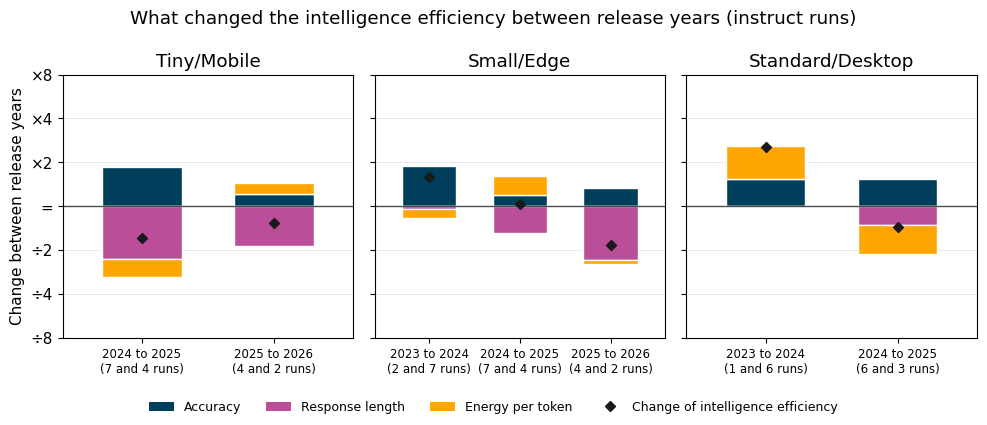

Accuracy  Response length  \
category         step         runs                                 
Tiny/Mobile      2024 to 2025 7 and 4      1.85             0.43   
                 2025 to 2026 4 and 2      1.21             0.53   
Small/Edge       2023 to 2024 2 and 7      1.89             0.95   
                 2024 to 2025 7 and 4      1.20             0.65   
                 2025 to 2026 4 and 2      1.34             0.43   
Standard/Desktop 2023 to 2024 1 and 6      1.55             0.98   
                 2024 to 2025 6 and 3      1.53             0.74   

                                       Energy per token   Net  
category         step         runs                             
Tiny/Mobile      2024 to 2025 7 and 4              0.76  0.61  
                 2025 to 2026 4 and 2              1.19  0.76  
Small/Edge       2023 to 2024 2 and 7              0.88  1.58  
                 2024 to 2025 7 and 4              1.34  1.04  
                 2025 to 2026 4 and 2              0.94  0.54  
Standard/Desktop 2023 to 2024 1 and 6              1.67  2.54  
                 2024 to 2025 6 and 3              0.63  0.72

In [11]:
rows = []
for category in CATEGORY_ORDER:
    runs = instruct[instruct["category"] == category]
    years = sorted(runs["year"].unique())
    for before_year, after_year in zip(years[:-1], years[1:]):
        before, after = runs[runs["year"] == before_year], runs[runs["year"] == after_year]
        rows.append({
            "category": category,
            "step": f"{before_year} to {after_year}",
            "runs": f"{len(before)} and {len(after)}",
            **contributions(before, after),
        })
by_year = pd.DataFrame(rows)
assert np.allclose(by_year[list(FACTOR_COLORS)].sum(axis=1), by_year["Net"])

fig, axes = category_panels(figsize=(10, 4.2), sharex=False)
for ax, category in zip(axes[0], CATEGORY_ORDER):
    table = by_year[by_year["category"] == category]
    positions = stacked_contributions(ax, table)
    ax.set_xticks(positions, labels=[f"{step}\n({runs} runs)" for step, runs in zip(table["step"], table["runs"])], fontsize=8.5)
    ax.set_xlim(-0.6, max(len(table), 2) - 0.4)
    ax.grid(axis="x", visible=False)
axes[0][0].set_ylabel("Change between release years")
fig.suptitle("What changed the intelligence efficiency between release years (instruct runs)")
fig.legend(handles=FACTOR_HANDLES, loc="lower center", ncol=4, fontsize=9, frameon=False)
plt.tight_layout(rect=(0, 0.07, 1, 1))
save_chart(fig, "rq1-decomposition-by-year")
plt.show()

factors = by_year.set_index(["category", "step", "runs"])
np.exp(factors).round(2)

### 8. Energy per Token at Equal Size
The energy per token depends mostly on the size of the model. We fit a power law of the GPU energy per generated token on the active parameters, using one value per model, and plot how far each model run is from it against the release date.

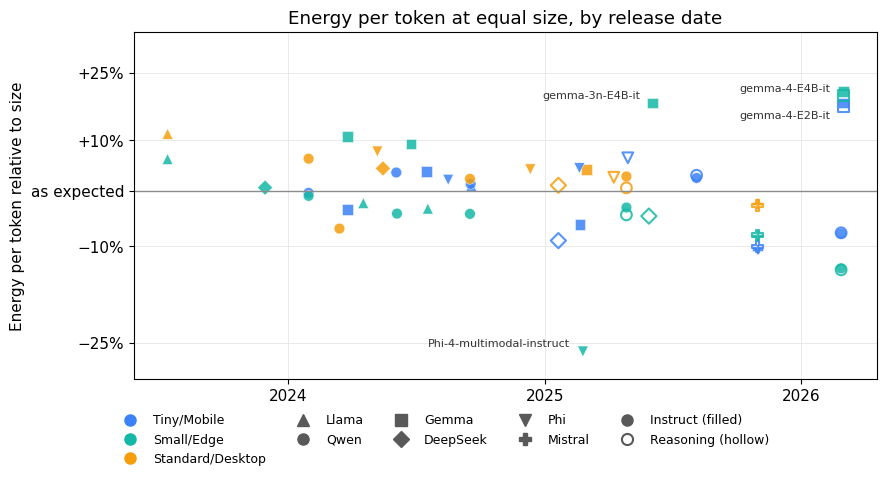

Fit: energy per token = 1.03 J x (active parameters in billions) ^ 0.91   R2 = 0.980   models: 47
Association between the release date and the distance to the fit: Spearman correlation = -0.17 (p = 0.224)


In [12]:
per_model = model_runs.groupby("model").agg(
    activated_parameters=("activated_parameters", "first"),
    gpu_joules_per_generated_token=("gpu_joules_per_generated_token", "mean"),
)
x = np.log(per_model["activated_parameters"])
y = np.log(per_model["gpu_joules_per_generated_token"])
exponent, intercept = np.polyfit(x, y, 1)
r_squared = 1 - ((y - (intercept + exponent * x)) ** 2).sum() / ((y - y.mean()) ** 2).sum()

expected = np.exp(intercept + exponent * np.log(model_runs["activated_parameters"]))
model_runs["energy_per_token_vs_size"] = model_runs["gpu_joules_per_generated_token"] / expected

fig, ax = plt.subplots(figsize=(9, 4.8))
ax.axhline(1, color="0.55", linewidth=1)
scatter_model_runs(ax, model_runs, "release_date", "energy_per_token_vs_size")
# Labels of the models that are more than 15% away from the fit, one below the other when released on the same date
far = model_runs[(model_runs["energy_per_token_vs_size"] - 1).abs() > 0.15].drop_duplicates("model")
far = far.sort_values("energy_per_token_vs_size", ascending=False)
for (_, run), row in zip(far.iterrows(), far.groupby("release_date").cumcount()):
    ax.annotate(run["model"].split("/")[-1], (run["release_date"], run["energy_per_token_vs_size"]), xytext=(-9, 3 - 12 * row), textcoords="offset points", ha="right", fontsize=8, color="0.2")
ax.set_yscale("log")
ax.set_ylim(0.7, 1.35)
ax.set_yticks([0.75, 0.9, 1, 1.1, 1.25], labels=["−25%", "−10%", "as expected", "+10%", "+25%"])
ax.minorticks_off()
format_year_axis(ax)
ax.set_ylabel("Energy per token relative to size")
ax.set_title("Energy per token at equal size, by release date")
fig.legend(handles=legend_handles(families=FAMILIES), loc="lower center", ncol=5, fontsize=9, frameon=False)
plt.tight_layout(rect=(0, 0.11, 1, 1))
save_chart(fig, "rq1-energy-per-token-at-equal-size")
plt.show()

correlation, p_value = spearmanr(model_runs["years"], model_runs["energy_per_token_vs_size"])
print(f"Fit: energy per token = {np.exp(intercept):.2f} J x (active parameters in billions) ^ {exponent:.2f}   R2 = {r_squared:.3f}   models: {len(per_model)}")
print(f"Association between the release date and the distance to the fit: Spearman correlation = {correlation:.2f} (p = {p_value:.3f})")

We then split the energy per token contribution of each lineage step into two parts: the change of size of the model, given by the fit, and the change at equal size.

In [13]:
log_expected = pd.Series(np.log(expected).to_numpy(), index=model_runs["model_run"])
size = -(steps["to_run"].map(log_expected) - steps["from_run"].map(log_expected))

size_split = steps[["category", "family", "from", "to"]].copy()
size_split["Energy per token"] = np.exp(steps["Energy per token"]).round(2)
size_split["Size of the model"] = np.exp(size).round(2)
size_split["At equal size"] = np.exp(steps["Energy per token"] - size).round(2)
within_10 = int(((size_split["At equal size"] - 1).abs() <= 0.10).sum())
print(f"Steps where the energy per token at equal size changed by 10% or less: {within_10} of {len(size_split)}")
size_split

Steps where the energy per token at equal size changed by 10% or less: 15 of 18


,category,family,from,to,Energy per token,Size of the model,At equal size
0,Tiny/Mobile,Gemma,gemma-1.1-2b-it,gemma-2-2b-it,0.90,0.97,0.93
1,Tiny/Mobile,Gemma,gemma-2-2b-it,gemma-3-4b-it,0.70,0.63,1.10
2,Tiny/Mobile,Phi,Phi-3.5-mini-instruct,Phi-4-mini-instruct,0.97,1.00,0.98
3,Tiny/Mobile,Qwen,Qwen1.5-4B-Chat,Qwen2-1.5B-Instruct,2.27,2.36,0.96
4,Tiny/Mobile,Qwen,Qwen2-1.5B-Instruct,Qwen2.5-3B-Instruct,0.54,0.53,1.02
5,Tiny/Mobile,Qwen,Qwen2.5-3B-Instruct,Qwen3-4B-Instruct-2507,0.78,0.79,0.99
6,Tiny/Mobile,Qwen,Qwen3-4B-Instruct-2507,Qwen3.5-4B (I),0.97,0.87,1.11
7,Small/Edge,Gemma,gemma-1.1-7b-it,gemma-2-9b-it,0.94,0.93,1.01
8,Small/Edge,Gemma,gemma-3n-E4B-it,gemma-4-E4B-it (I),0.98,1.00,0.98
9,Small/Edge,Llama,Llama-2-7b-chat-hf,Meta-Llama-3-8B-Instruct,0.93,0.85,1.09


### 9. Pareto Front per Year
We find the Pareto front of the model runs released until the end of each year: the runs for which no other run released until then is both cheaper and more accurate. Each front is drawn over the accuracy and GPU energy per question of every model run, from the lightest line (first year) to the darkest (last year). A front includes the model runs of the previous years that were not surpassed, so the fronts of different years coincide in some parts, where only the most recent one is visible.

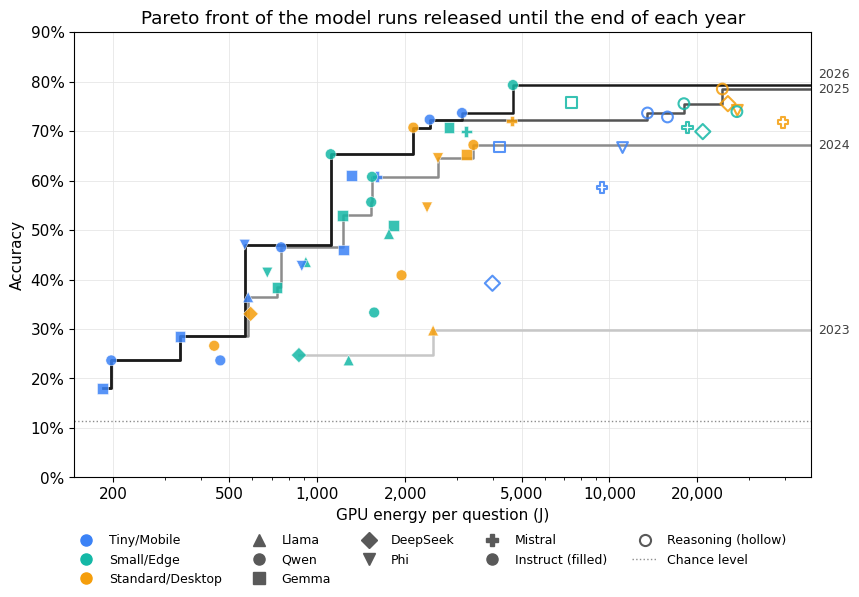

Released  Accuracy  \
Until the end of Model run                                      
2023             deepseek-llm-7b-chat    2023-11-29     0.247   
                 Llama-2-13b-chat-hf     2023-07-13     0.297   
2024             gemma-1.1-2b-it         2024-03-26     0.180   
                 Qwen2-1.5B-Instruct     2024-06-03     0.237   
                 gemma-2-2b-it           2024-07-16     0.285   
                 Llama-3.2-3B-Instruct   2024-09-18     0.364   
                 gemma-1.1-7b-it         2024-03-26     0.384   
                 Qwen2.5-3B-Instruct     2024-09-17     0.465   
                 gemma-2-9b-it           2024-06-24     0.530   
                 Qwen2-7B-Instruct       2024-06-04     0.556   
                 Qwen2.5-7B-Instruct     2024-09-16     0.608   
                 phi-4                   2024-12-11     0.645   
                 Qwen2.5-14B-Instruct    2024-09-16     0.672   
2025             gemma-1.1-2b-it         2024-03-26     0.180   
                 Qwen2-1.5B-Instruct     2024-06-03     0.237   
                 gemma-2-2b-it           2024-07-16     0.285   
                 Phi-4-mini-instruct     2025-02-19     0.470   
                 Qwen3-8B (I)            2025-04-27     0.653   
                 Qwen3-14B (I)           2025-04-27     0.707   
                 Qwen3-4B-Instruct-2507  2025-08-05     0.723   
                 Qwen3-4B-Thinking-2507  2025-08-05     0.737   
                 Qwen3-8B (R)            2025-04-27     0.755   
                 Qwen3-14B (R)           2025-04-27     0.785   
2026             gemma-1.1-2b-it         2024-03-26     0.180   
                 Qwen2-1.5B-Instruct     2024-06-03     0.237   
                 gemma-2-2b-it           2024-07-16     0.285   
                 Phi-4-mini-instruct     2025-02-19     0.470   
                 Qwen3-8B (I)            2025-04-27     0.653   
                 Qwen3-14B (I)           2025-04-27     0.707   
                 Qwen3-4B-Instruct-2507  2025-08-05     0.723   
                 Qwen3.5-4B (I)          2026-02-27     0.737   
                 Qwen3.5-9B (I)          2026-02-27     0.793   

                                         GPU energy per question (J)  \
Until the end of Model run                                             
2023             deepseek-llm-7b-chat                            865   
                 Llama-2-13b-chat-hf                            2491   
2024             gemma-1.1-2b-it                                 184   
                 Qwen2-1.5B-Instruct                             197   
                 gemma-2-2b-it                                   339   
                 Llama-3.2-3B-Instruct                           580   
                 gemma-1.1-7b-it                                 728   
                 Qwen2.5-3B-Instruct                             752   
                 gemma-2-9b-it                                  1221   
                 Qwen2-7B-Instruct                              1529   
                 Qwen2.5-7B-Instruct                            1539   
                 phi-4                                          2588   
                 Qwen2.5-14B-Instruct                           3422   
2025             gemma-1.1-2b-it                                 184   
                 Qwen2-1.5B-Instruct                             197   
                 gemma-2-2b-it                                   339   
                 Phi-4-mini-instruct                             564   
                 Qwen3-8B (I)                                   1111   
                 Qwen3-14B (I)                                  2131   
                 Qwen3-4B-Instruct-2507                         2425   
                 Qwen3-4B-Thinking-2507                        13491   
                 Qwen3-8B (R)                                  17973   
                 Qwen3-14B (R)                                 24329   
2026             gemma-1.1-2b-it

In [14]:
YEARS = sorted(model_runs["year"].unique())
YEAR_SHADES = dict(zip(YEARS, np.linspace(0.78, 0.1, len(YEARS)).round(2).astype(str)))
max_energy = 1.25 * model_runs["gpu_joules_per_question"].max()

fig, ax = plt.subplots(figsize=(9, 6))
ax.axhline(CHANCE_LEVEL, color="0.55", linewidth=1, linestyle=":")
scatter_model_runs(ax, model_runs, "gpu_joules_per_question", "accuracy", zorder=2)

fronts = {}
for year in YEARS:
    released = model_runs[model_runs["release_date"].dt.year <= year]
    fronts[year] = pareto_front(released, "gpu_joules_per_question", "accuracy")
    # The front continues to the right at the accuracy of its most accurate run
    energy = list(fronts[year]["gpu_joules_per_question"]) + [max_energy]
    accuracy = list(fronts[year]["accuracy"]) + [fronts[year]["accuracy"].iloc[-1]]
    ax.plot(energy, accuracy, drawstyle="steps-post", color=YEAR_SHADES[year], linewidth=1.8, zorder=1)

# Year of each front at its right end, moved apart where two fronts end close together
label_height = 0
for year in sorted(YEARS, key=lambda year: fronts[year]["accuracy"].max()):
    label_height = max(fronts[year]["accuracy"].max(), label_height + 0.03)
    ax.annotate(str(year), (max_energy, label_height), xytext=(5, 0), textcoords="offset points", va="center", fontsize=9, color="0.25", annotation_clip=False)

ax.set_xscale("log")
ax.set_xlim(0.8 * model_runs["gpu_joules_per_question"].min(), max_energy)
ax.set_ylim(0, 0.9)
percent_axis(ax.yaxis)
plain_log_axis(ax.xaxis)
ax.set_xlabel("GPU energy per question (J)")
ax.set_ylabel("Accuracy")
ax.set_title("Pareto front of the model runs released until the end of each year")
handles = legend_handles(families=FAMILIES) + [Line2D([], [], color="0.55", linewidth=1, linestyle=":", label="Chance level")]
fig.legend(handles=handles, loc="lower center", ncol=5, fontsize=9, frameon=False)
plt.tight_layout(rect=(0, 0.09, 0.97, 1))
save_chart(fig, "rq1-pareto-front-per-year")
plt.show()

rows = []
for year, front in fronts.items():
    for _, run in front.iterrows():
        rows.append({"Until the end of": year, "Model run": short_name(run["model_run"]), "Released": run["release_date"].date(), "Accuracy": round(run["accuracy"], 3), "GPU energy per question (J)": round(run["gpu_joules_per_question"]), "Correct answers per kJ": round(run["correct_answers_per_kj"], 3)})
front_table = pd.DataFrame(rows)
front_table.set_index(["Until the end of", "Model run"])

### 10. Accuracy within an Energy Budget
For every energy budget per question and every month, we find the best accuracy among the model runs released so far that stay within the budget. The hatched area has no model run within the budget.

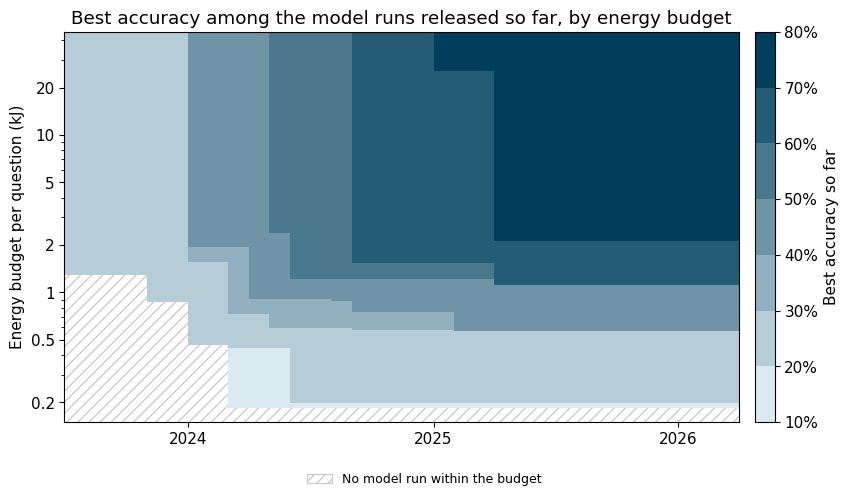

In [15]:
months = pd.date_range(model_runs["release_date"].min().to_period("M").to_timestamp(), last_date + pd.offsets.MonthBegin(1), freq="MS")
LOWEST_BUDGET, HIGHEST_BUDGET = 0.15, 45

levels = np.arange(0.1, 0.81, 0.1)
colormap = LinearSegmentedColormap.from_list("accuracy", ["#dbe9f0", TARGET_COLORS[-1]], N=len(levels) - 1)
norm = BoundaryNorm(levels, colormap.N)

fig, ax = plt.subplots(figsize=(9, 5))
ax.patch.set(hatch="///", edgecolor="0.8")
# One area per level of accuracy, from the lowest to the highest: in each month, the budgets that are enough
# for a model run released until then to reach that accuracy
for level in levels[:-1]:
    lowest_budget = []
    for month_end in months[1:]:
        reaching = model_runs[(model_runs["release_date"] < month_end) & (model_runs["accuracy"] >= level)]
        lowest_budget.append(reaching["gpu_joules_per_question"].min() / 1000 if len(reaching) else HIGHEST_BUDGET)
    ax.fill_between(months, lowest_budget + lowest_budget[-1:], HIGHEST_BUDGET, step="post", color=colormap(norm(level + 0.05)), linewidth=0)
ax.set_yscale("log")
plain_log_axis(ax.yaxis)
ax.set_ylim(LOWEST_BUDGET, HIGHEST_BUDGET)
ax.set_xlim(months[0], months[-1])
format_year_axis(ax)
ax.grid(False)
ax.set_ylabel("Energy budget per question (kJ)")
ax.set_title("Best accuracy among the model runs released so far, by energy budget")
colorbar = fig.colorbar(plt.cm.ScalarMappable(norm=norm, cmap=colormap), ax=ax, pad=0.02)
colorbar.set_label("Best accuracy so far")
percent_axis(colorbar.ax.yaxis)
fig.legend(handles=[Patch(facecolor="w", edgecolor="0.8", hatch="///", label="No model run within the budget")], loc="lower center", fontsize=9, frameon=False)
plt.tight_layout(rect=(0, 0.06, 1, 1))
save_chart(fig, "rq1-accuracy-within-budget")
plt.show()

### 11. Earlier and Later Models
We compare, in each size category, the instruct runs released until the end of 2024 with those released afterwards, in two ways. The first is the median of their accuracy, energy per question and intelligence efficiency. The second is the best accuracy among the instruct runs of the category released until the end of each period that stay within each energy budget.

In [16]:
PERIODS = {"Until the end of 2024": instruct["release_date"] < "2025-01-01", "2025 and 2026": instruct["release_date"] >= "2025-01-01"}

rows = []
for category in CATEGORY_ORDER:
    for period, in_period in PERIODS.items():
        group = instruct[in_period & (instruct["category"] == category)]
        # Instruct runs of the category released until the end of the period
        released = instruct[(instruct["category"] == category) & (instruct["release_date"] <= group["release_date"].max())]
        row = {
            "Category": category,
            "Released": period,
            "Model runs": len(group),
            "Median accuracy": group["accuracy"].median(),
            "Median energy per question (J)": group["gpu_joules_per_question"].median(),
            "Median correct answers per kJ": group["correct_answers_per_kj"].median(),
        }
        for budget in BUDGETS_KJ:
            within = released[released["gpu_joules_per_question"] <= budget * 1000]
            row[f"Best accuracy within {budget:g} kJ"] = within["accuracy"].max() if len(within) else np.nan
        rows.append(row)
periods = pd.DataFrame(rows).set_index(["Category", "Released"])
periods.round({"Median accuracy": 3, "Median energy per question (J)": 0, "Median correct answers per kJ": 3} | {f"Best accuracy within {budget:g} kJ": 3 for budget in BUDGETS_KJ}).T

Category                                 Tiny/Mobile                \
Released                       Until the end of 2024 2025 and 2026   
Model runs                                     7.000         6.000   
Median accuracy                                0.285         0.609   
Median energy per question (J)               466.000      1454.000   
Median correct answers per kJ                  0.636         0.376   
Best accuracy within 0.5 kJ                    0.285         0.285   
Best accuracy within 1 kJ                      0.465         0.470   
Best accuracy within 2 kJ                      0.465         0.610   
Best accuracy within 5 kJ                      0.465         0.737   

Category                                  Small/Edge                \
Released                       Until the end of 2024 2025 and 2026   
Model runs                                     9.000         6.000   
Median accuracy                                0.435         0.676   
Median energy per question (J)              1280.000      2322.000   
Median correct answers per kJ                  0.364         0.265   
Best accuracy within 0.5 kJ                      NaN           NaN   
Best accuracy within 1 kJ                      0.435         0.435   
Best accuracy within 2 kJ                      0.608         0.653   
Best accuracy within 5 kJ                      0.608         0.793   

Category                            Standard/Desktop                
Released                       Until the end of 2024 2025 and 2026  
Model runs                                     7.000         3.000  
Median accuracy                                0.409         0.707  
Median energy per question (J)              2374.000      3234.000  
Median correct answers per kJ                  0.230         0.202  
Best accuracy within 0.5 kJ                    0.266         0.266  
Best accuracy within 1 kJ                      0.331         0.331  
Best accuracy within 2 kJ                      0.409         0.409  
Best accuracy within 5 kJ                      0.672         0.720

### 12. Typical Response Length
The generated tokens per question of a model run are a mean over its 372 questions. We compare this mean with the median over the questions, for the instruct runs of each release year, and estimate the yearly change of both in each size category.

In [17]:
# Median, over the questions of each model run, of the generated tokens of a question
typical = questions.groupby("model_run")["generated_tokens_median"].median().rename("median_generated_tokens")
response_length = instruct.merge(typical, left_on="model_run", right_index=True)

by_year = response_length.groupby("year").agg(
    runs=("model_run", "size"),
    mean_tokens=("generated_tokens_per_question", "median"),
    median_tokens=("median_generated_tokens", "median"),
)
print("Median instruct run of each release year: mean and median generated tokens of a question")
print(by_year.round(0).to_string())

rows = []
for category in CATEGORY_ORDER:
    runs = response_length[response_length["category"] == category]
    for name, column in {"Mean": "generated_tokens_per_question", "Median": "median_generated_tokens"}.items():
        slope, correlation, p_value = yearly_change(runs, column, True)
        rows.append({"Category": category, "Tokens of a question": name, "Yearly change": f"×{slope:.2f}", "Spearman correlation": round(correlation, 2), "p": round(p_value, 3)})
pd.DataFrame(rows).set_index(["Category", "Tokens of a question"])

Median instruct run of each release year: mean and median generated tokens of a question
      runs  mean_tokens  median_tokens
year                                  
2023     3        207.0          125.0
2024    20        194.0          106.0
2025    11        339.0          152.0
2026     4        657.0          444.0


Yearly change  Spearman correlation  \
Category         Tokens of a question                                       
Tiny/Mobile      Mean                         ×2.56                  0.91   
                 Median                       ×2.37                  0.80   
Small/Edge       Mean                         ×1.73                  0.69   
                 Median                       ×1.70                  0.65   
Standard/Desktop Mean                         ×1.30                  0.47   
                 Median                       ×1.29                  0.56   

                                           p  
Category         Tokens of a question         
Tiny/Mobile      Mean                  0.000  
                 Median                0.001  
Small/Edge       Mean                  0.004  
                 Median                0.009  
Standard/Desktop Mean                  0.174  
                 Median                0.093

### 13. Examples of the Prompt
The prompt of an instruct run contains five examples of the subject of the question, each with a worked answer. We compare the length of these answers with the length of the responses of the instruct runs, in words, using the first repetition of each model run. The examples are those of the validation split of MMLU-Pro, whose lengths are saved in `data/prompt_examples.csv` the first time this step runs.

In [18]:
import json
from urllib.request import urlopen

from common import DATA_DIR, RESULTS_DIRS, load_repetitions

EXAMPLES_FILE = DATA_DIR / "prompt_examples.csv"
if not EXAMPLES_FILE.exists():
    url = "https://datasets-server.huggingface.co/rows?dataset=TIGER-Lab%2FMMLU-Pro&config=default&split=validation&offset=0&length=100"
    examples = pd.DataFrame([row["row"] for row in json.load(urlopen(url, timeout=60))["rows"]])
    examples["answer_words"] = examples["cot_content"].str.split().str.len()
    examples[["question_id", "category", "answer_words"]].to_csv(EXAMPLES_FILE, index=False)
examples = pd.read_csv(EXAMPLES_FILE)
example_words = examples["answer_words"].median()
print(f"Examples: {len(examples)} ({examples.groupby('category').size().iloc[0]} per subject); words of their answers: median {example_words:.0f}, mean {examples['answer_words'].mean():.0f}, {examples['answer_words'].min()} to {examples['answer_words'].max()}")

# Words of the responses of the first repetition of each instruct run
first_runs = load_repetitions(instruct).sort_values("repetition").groupby("model_run")["run"].first()
rows = []
for _, run in instruct.iterrows():
    run_dir = RESULTS_DIRS[run["execution"]] / first_runs[run["model_run"]]
    words = [len((record["model_outputs"] or "").split()) for path in sorted(run_dir.glob("*/CoT/all/*.json")) for record in json.load(open(path))]
    rows.append({"model_run": run["model_run"], "year": run["year"], "responses": len(words), "median_words": np.median(words)})
response_words = pd.DataFrame(rows)
assert (response_words["responses"] == len(questions["question_id"].unique())).all()

shorter = (response_words["median_words"] < example_words).sum()
print(f"Instruct runs whose median response is shorter than the median answer of the examples: {shorter} of {len(response_words)}")
by_year = response_words.groupby("year")["median_words"].agg(["size", "min", "median", "max"]).rename(columns={"size": "runs"})
by_year["median against the examples"] = by_year["median"] / example_words
print("\nWords of the median response of the instruct runs, by release year:")
print(by_year.round(1).to_string())

Examples: 70 (5 per subject); words of their answers: median 54, mean 61, 24 to 192
Instruct runs whose median response is shorter than the median answer of the examples: 2 of 38

Words of the median response of the instruct runs, by release year:
      runs    min  median    max  median against the examples
year                                                         
2023     3   63.0    75.0   85.0                          1.4
2024    20   43.5    76.0  133.5                          1.4
2025    11   71.5   105.0  276.0                          2.0
2026     4  233.0   258.5  295.5                          4.8


### 14. Key Values

In [19]:
print("Yearly change among the instruct runs:")
print(trends.to_string(index=False))

print("\nYearly change among the dense instruct runs:")
print(dense_trends.to_string(index=False))

print("\nMedian of the instruct runs by release year:")
medians = instruct.groupby("year").agg(
    runs=("model_run", "size"),
    accuracy=("accuracy", "median"),
    gpu_joules_per_question=("gpu_joules_per_question", "median"),
    generated_tokens_per_question=("generated_tokens_per_question", "median"),
    gpu_joules_per_generated_token=("gpu_joules_per_generated_token", "median"),
    correct_answers_per_kj=("correct_answers_per_kj", "median"),
)
print(medians.round(3).to_string())

print(f"\nLineage steps: {len(steps)}; intelligence efficiency improved in {improved}")
print(f"Lineage steps where the energy per token at equal size changed by 10% or less: {within_10}")
print(f"Energy per token against active parameters: exponent {exponent:.2f}, R2 {r_squared:.3f}")

print("\nEarlier and later instruct runs of each size category:")
print(periods.round(3).T.to_string())

print("\nGenerated tokens per question of the instruct runs released before and since June 2025:")
for label, group in {"before": instruct[instruct["release_date"] < "2025-06-01"], "since": instruct[instruct["release_date"] >= "2025-06-01"]}.items():
    tokens = group["generated_tokens_per_question"]
    print(f"  {label}: {len(group)} runs, {tokens.min():.0f} to {tokens.max():.0f} (median {tokens.median():.0f})")

print("\nInstruct runs released after 2024 that stay within each energy budget:")
later = instruct[instruct["release_date"] >= "2025-01-01"]
for budget in BUDGETS_KJ:
    print(f"  {budget:g} kJ: {(later['gpu_joules_per_question'] <= budget * 1000).sum()} of {len(later)}")

print("\nModel runs on the Pareto front until the end of each year:")
for year, year_front in fronts.items():
    print(f"  {year}: {len(year_front)} runs, accuracy up to {year_front['accuracy'].max():.3f}, {(year_front['mode'] == 'Reasoning').sum()} reasoning runs")

Yearly change among the instruct runs:
        Category                         Metric  Model runs Yearly change  Spearman correlation     p
     Tiny/Mobile                       Accuracy          13  +23.9 points                  0.92 0.000
     Tiny/Mobile        GPU energy per question          13         ×2.84                  0.87 0.000
     Tiny/Mobile  Generated tokens per question          13         ×2.56                  0.91 0.000
     Tiny/Mobile GPU energy per generated token          13         ×1.11                  0.36 0.223
     Tiny/Mobile         Correct answers per kJ          13         ×0.62                 -0.74 0.004
      Small/Edge                       Accuracy          15  +17.9 points                  0.87 0.000
      Small/Edge        GPU energy per question          15         ×1.57                  0.59 0.020
      Small/Edge  Generated tokens per question          15         ×1.73                  0.69 0.004
      Small/Edge GPU energy per generated t